# PAN Lines theme extraction: walkthrough on a sample

Post-discharge nurse call notes classified into a controlled taxonomy, step by step, on a small
sample of encounters. Each section is one step of the pipeline, done in the open so you can see
what the governed objects do under the hood.

| Step | What it does | Where it lives |
|---|---|---|
| 1. Data prep | roll note lines up to one row per encounter | `ENCOUNTER_PREP` dynamic table |
| 2. Taxonomy | category > theme > subtheme, versioned | `TAXONOMY_VERSION`, `TAXONOMY_RENDERED` |
| 3. Classification | one set-based `AI_COMPLETE` with an enum response schema | `RUN_CLASSIFIER` |
| 4. Checks | out-of-taxonomy count, gold scoring, gap signal, cost | `EVAL_GATE`, `TAXONOMY_GAP_REVIEW`, `RUN_COST` |

Everything here uses the **champion**: the one classifier config in production. A config is the
whole recipe, prompt + model + taxonomy version, and it only became the champion by passing an
evaluation gate (section 11).

**What this writes:** session `TEMPORARY` tables only (`DEMO_SAMPLE`, `DEMO_RESULT`, `DEMO_FREE`),
so the pipeline tables and the webapp warm-start state are untouched. The one exception is the
optional section 11, which is off by default.

**Cost:** about 20 `claude-haiku-4-5` calls with the default sample. Runs in about a minute.

Runs locally (uses your default Snowflake connection; set `SNOWFLAKE_CONNECTION_NAME` to pick
another) or in a Snowflake Workspace.

In [ ]:
import os, re, json, time
import pandas as pd
import matplotlib.pyplot as plt

try:
    from snowflake.snowpark.context import get_active_session
    session = get_active_session()
    print("Connected via Snowflake Workspace")
except Exception:
    from snowflake.snowpark import Session
    # Uses SNOWFLAKE_CONNECTION_NAME if set, otherwise your default connection.
    name = os.getenv("SNOWFLAKE_CONNECTION_NAME")
    session = (Session.builder.config("connection_name", name) if name else Session.builder).create()
    print("Connected locally")

# ---- Demo knobs ---------------------------------------------------------------
DATABASE         = "PAN_DEMO_DB"
SCHEMA           = "PIPELINE"   # the pipeline schema; everything scored here comes from it
TEST_DATA        = "PAN_DEMO_DB.SYNTHETIC_DATA"  # test-data tags, used only to pick and describe the sample
WAREHOUSE        = "PAN_DEMO_WH"
SAMPLE_PER_SCENARIO = 2   # gold encounters per test scenario (5 scenarios -> 10 encounters)
SAMPLE_SEED      = 42     # change for a different, still reproducible, sample
RUN_NO_ENUM_COMPARISON = True   # section 7b: same prompt, no enum (another ~10 calls)
RUN_GOVERNED_PATH      = False  # section 11: WRITES to pipeline tables, see the note there

# Interpolated into SQL below, so pin them to safe types/values.
SAMPLE_PER_SCENARIO = int(SAMPLE_PER_SCENARIO)
SAMPLE_SEED      = int(SAMPLE_SEED)
assert 1 <= SAMPLE_PER_SCENARIO <= 20, "keep the sample small, this is a demo"

session.sql(f"USE WAREHOUSE {WAREHOUSE}").collect()
session.sql(f"USE SCHEMA {DATABASE}.{SCHEMA}").collect()

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 220)

def q(sql, params=None):
    """Run a bounded query and return pandas with lowercase column names."""
    df = session.sql(sql, params=params).to_pandas()
    df.columns = [c.lower() for c in df.columns]
    return df

def show(sql, cols):
    """SHOW commands: read selected columns back through RESULT_SCAN (SHOW + to_pandas is unreliable)."""
    session.sql(sql).collect()
    col_list = ", ".join(f'"{c}"' for c in cols)
    return q(f"SELECT {col_list} FROM TABLE(RESULT_SCAN(LAST_QUERY_ID()))")

q("SELECT CURRENT_ROLE() AS role, CURRENT_WAREHOUSE() AS warehouse, CURRENT_SCHEMA() AS schema")

Connected locally


,role,warehouse,schema
0,SYSADMIN,PAN_DEMO_WH,PIPELINE


## 1. The raw data

`NOTE_RAW` is note-level, the shape the source system hands over: one row per note line, and some
encounters have more than one. Notes are synthetic, generated from a seeded scenario spec, so there
is no PHI.

In [2]:
display(q("""
    SELECT COUNT(*)                     AS note_rows,
           COUNT(DISTINCT encounter_id) AS encounters,
           ROUND(AVG(LENGTH(note_text))) AS avg_note_chars
    FROM NOTE_RAW
"""))

# One multi-note encounter, to show why step 1 exists.
q("""
    SELECT encounter_id, note_seq, discharge_date, call_date, note_text
    FROM NOTE_RAW
    WHERE encounter_id = (SELECT encounter_id FROM NOTE_RAW
                          GROUP BY encounter_id HAVING COUNT(*) > 1
                          ORDER BY encounter_id LIMIT 1)
    ORDER BY note_seq
""")

,note_rows,encounters,avg_note_chars
0,1260,1000,397


,encounter_id,note_seq,discharge_date,call_date,note_text
0,ENC-00003,1,2026-09-17,2026-10-05,"Pt called in AM, got VM, left message requesting callback this week. Pt called back approx 2pm same day."
1,ENC-00003,2,2026-09-17,2026-10-05,"Pt called back after we left VM. Doing okay overall he says, weather has been nice where he is. Mentioned wife has been helping him a lot at home which is g..."


## 2. Pick a demo sample

A stratified sample from the **200 gold encounters**, so every result can be scored against a
label at the end. Synthetic notes are only a fair test if they aren't all easy, so each one was
generated from a **test scenario**, and this takes `SAMPLE_PER_SCENARIO` from each:

- **STRAIGHTFORWARD**: one clear concern
- **NEAR_NEIGHBOUR**: the note includes a cue for a similar subtheme
- **MULTI_LABEL**: seeded with two distinct concerns
- **GAP**: a concept left out of the taxonomy's design sample, so v001 doesn't have it (transportation)
- **AMBIGUOUS**: written to be ambiguous between two subthemes

The scenario is **test data**: it comes from `SYNTHETIC_DATA.TEST_SCENARIO`, describes how the
synthetic note was built, and doesn't exist on real data. The pipeline never reads it, and the
classifier only gets the note text. The production evaluation scores by segments it can derive
from real data instead (category, label count, note length; section 11).

In [3]:
session.sql(f"""
    CREATE OR REPLACE TEMPORARY TABLE DEMO_SAMPLE AS
    SELECT g.encounter_id, ts.test_scenario
    FROM GOLD_ENCOUNTER g
    JOIN {TEST_DATA}.TEST_SCENARIO ts ON ts.encounter_id = g.encounter_id
    QUALIFY ROW_NUMBER() OVER (PARTITION BY ts.test_scenario
                               ORDER BY HASH(g.encounter_id, {SAMPLE_SEED})) <= {SAMPLE_PER_SCENARIO}
""").collect()

sample = q("SELECT * FROM DEMO_SAMPLE ORDER BY test_scenario, encounter_id")
print(f"{len(sample)} encounters")
sample

10 encounters


,encounter_id,test_scenario
0,ENC-00197,AMBIGUOUS
1,ENC-00200,AMBIGUOUS
2,ENC-00171,GAP
3,ENC-00180,GAP
4,ENC-00155,MULTI_LABEL
5,ENC-00160,MULTI_LABEL
6,ENC-00121,NEAR_NEIGHBOUR
7,ENC-00147,NEAR_NEIGHBOUR
8,ENC-00015,STRAIGHTFORWARD
9,ENC-00114,STRAIGHTFORWARD


## 3. Step 1, prep: roll notes up to one row per encounter

The rollup is a **dynamic table**. It is declarative and refreshes incrementally,
so new notes flow in with no code to run. No LLM is involved in this step.

In [4]:
display(q("""
    SELECT d.encounter_id,
           COUNT(*)              AS raw_note_rows,
           ANY_VALUE(p.note_count) AS prep_note_count,
           ANY_VALUE(LENGTH(p.full_text)) AS prep_chars
    FROM DEMO_SAMPLE d
    JOIN NOTE_RAW       r ON r.encounter_id = d.encounter_id
    JOIN ENCOUNTER_PREP p ON p.encounter_id = d.encounter_id
    GROUP BY d.encounter_id
    ORDER BY raw_note_rows DESC, d.encounter_id
"""))

# Resolved refresh mode must be INCREMENTAL: a FULL-refresh dynamic table cannot carry
# the stream that feeds the classification task.
show("SHOW DYNAMIC TABLES LIKE 'ENCOUNTER_PREP'",
     ["name", "target_lag", "refresh_mode", "scheduling_state", "warehouse"])

,encounter_id,raw_note_rows,prep_note_count,prep_chars
0,ENC-00155,2,2,276
1,ENC-00197,2,2,477
2,ENC-00015,1,1,188
3,ENC-00114,1,1,159
4,ENC-00121,1,1,274
5,ENC-00147,1,1,194
6,ENC-00160,1,1,474
7,ENC-00171,1,1,381
8,ENC-00180,1,1,1025
9,ENC-00200,1,1,769


,name,target_lag,refresh_mode,scheduling_state,warehouse
0,ENCOUNTER_PREP,1 minute,INCREMENTAL,ACTIVE,PAN_DEMO_WH


## 4. Step 2, the champion's taxonomy

The taxonomy was proposed by a model from a design sample of notes and landed as a DRAFT. A DRAFT
is editable and does nothing. Locking freezes it so it can be evaluated, and it reached production
only when a config bound to it was promoted past the eval gate. That config is the champion, and
its taxonomy version is the one with status APPROVED.

`TAXONOMY_RENDERED` turns any version into the two things the classifier uses:

- `taxonomy_text`: the rubric, `[CATEGORY] Theme > Subtheme: description (ROUTING: ...)`
- `response_format`: a JSON schema whose **enum is the subtheme list**

,config_name,model,taxonomy_version_id,status,category_count,theme_count,node_count,rubric_chars
0,haiku_enum_v1,claude-haiku-4-5,v001,APPROVED,8,23,78,21639


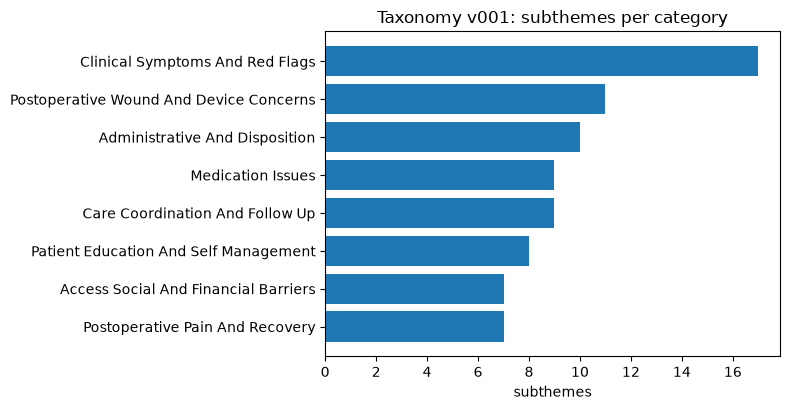

,category,theme,subtheme,description,routing_note
0,Access Social And Financial Barriers,Financial Barriers To Care,Medical Equipment Cost Concern,Patient is concerned about insurance coverage or out-of-pocket costs for durable medical equipment.,"If equipment is not delivered or not set up, code under Care Coordination And Follow Up."
1,Access Social And Financial Barriers,Financial Barriers To Care,Therapy Copay Barrier,"Patient cannot afford copays for physical therapy, cardiac rehabilitation, or outpatient therapy services.",
2,Access Social And Financial Barriers,Financial Barriers To Care,Visit Copay Barrier,"Patient cannot afford copays for clinic visits or follow-up appointments, leading to delayed evaluation.","If the cost barrier is for medications, use Medication Cost Barrier."
3,Access Social And Financial Barriers,Home And Social Environment,Housing Instability Affecting Recovery,"Housing is unstable, unsafe, or unsuitable for recovery (crowding, stairs, lack of bed, unsafe layout).","If the issue is specifically environmental hazards like mold or lack of heat, use Unsafe Home Environment Conditions."
4,Access Social And Financial Barriers,Home And Social Environment,Limited Access To Appropriate Foods,"Patient cannot reliably obtain foods compatible with prescribed diet due to cost, transportation, or availability.","If the issue is confusion about diet rules rather than access, use Diet Restrictions Clarification Needed."
5,Access Social And Financial Barriers,Home And Social Environment,Limited Caregiver Support At Home,"Patient lacks help at home for self-care tasks, equipment setup, or safe mobility during recovery.","If home health services were ordered but not started, use Home Health Services Not Started."
6,Access Social And Financial Barriers,Home And Social Environment,Unsafe Home Environment Conditions,"Home environment problems such as mold, water damage, extreme temperatures, or utility failures affecting health and recovery.",
7,Administrative And Disposition,Contact Status,,"Call outcomes where the follow-up could not be completed or the patient declined, or where the content is primarily administrative without a clinical, medic...",


In [5]:
champ = q("""
    SELECT c.config_name, c.model, c.taxonomy_version_id,
           t.status, t.category_count, t.theme_count, t.node_count,
           LENGTH(t.taxonomy_text) AS rubric_chars
    FROM ACTIVE_CONFIG c
    JOIN TAXONOMY_RENDERED t ON t.version_id = c.taxonomy_version_id
""")
display(champ)
assert len(champ) == 1, "no champion config: evaluate and promote one first (sql/04)"
CONFIG_NAME = champ.loc[0, "config_name"]
MODEL       = champ.loc[0, "model"]
TAX_VERSION = champ.loc[0, "taxonomy_version_id"]
# These three are interpolated into SQL below (AI_COMPLETE needs the model as a literal),
# so pin them to plain identifiers first.
for v in (CONFIG_NAME, MODEL, TAX_VERSION):
    assert re.fullmatch(r"[A-Za-z0-9][A-Za-z0-9_.\-]*", v), f"unexpected identifier {v!r}"

by_cat = q("""
    SELECT category, COUNT(DISTINCT theme) AS themes, COUNT(*) AS subthemes
    FROM TAXONOMY_NODE WHERE version_id = ? GROUP BY category ORDER BY subthemes
""", [TAX_VERSION])
fig, ax = plt.subplots(figsize=(8, 0.4 * len(by_cat) + 1))
ax.barh(by_cat["category"], by_cat["subthemes"])
ax.set_xlabel("subthemes")
ax.set_title(f"Taxonomy {TAX_VERSION}: subthemes per category")
plt.tight_layout()
plt.show()

q("""
    SELECT category, theme, subtheme, description, routing_note
    FROM TAXONOMY_NODE WHERE version_id = ? ORDER BY category, theme, subtheme LIMIT 8
""", [TAX_VERSION])

In [ ]:
# The enum: the model can only return one of these values.
rf = json.loads(session.sql("SELECT response_format FROM TAXONOMY_RENDERED WHERE version_id = ?",
                            params=[TAX_VERSION]).collect()[0][0])
props = rf["schema"]["properties"]
enum = props["primary_subtheme"]["enum"]

print(f"primary_subtheme enum: {len(enum)} values, NO_GOOD_MATCH included: {'NO_GOOD_MATCH' in enum}")
print(f"secondary_subtheme enum adds: {sorted(set(props['secondary_subtheme']['enum']) - set(enum))}")
print(f"confidence enum: {props['confidence']['enum']}")

preview = json.loads(json.dumps(rf))
for k in ("primary_subtheme", "secondary_subtheme"):
    e = preview["schema"]["properties"][k]["enum"]
    preview["schema"]["properties"][k]["enum"] = e[:3] + [f"... {len(e) - 4} more ..."] + e[-1:]
print(json.dumps(preview, indent=2))

primary_subtheme enum: 79 values, NO_GOOD_MATCH included: True
secondary_subtheme enum adds: ['NONE']
confidence enum: ['HIGH', 'MEDIUM', 'LOW']
{
  "schema": {
    "additionalProperties": false,
    "properties": {
      "confidence": {
        "enum": [
          "HIGH",
          "MEDIUM",
          "LOW"
        ],
        "type": "string"
      },
      "evidence": {
        "type": "string"
      },
      "primary_subtheme": {
        "enum": [
          "",
          "Activity Restrictions Clarification Needed",
          "Acute Confusion Or Delirium",
          "... 75 more ...",
          "NO_GOOD_MATCH"
        ],
        "type": "string"
      },
      "secondary_subtheme": {
        "enum": [
          "",
          "Activity Restrictions Clarification Needed",
          "Acute Confusion Or Delirium",
          "... 75 more ...",
          "NONE"
        ],
        "type": "string"
      }
    },
    "required": [
      "primary_subtheme",
      "secondary_subtheme",
      

In [ ]:
# The planted gap: v001 has no transportation subtheme. Section 9 comes back to this.
# (One description mentions transportation in passing, as a reason food is hard to get.
# That isn't a label that fits a missed-appointment-because-no-ride note.)
q("""
    SELECT COUNT_IF(subtheme ILIKE '%transport%')    AS subthemes_about_transport,
           COUNT_IF(description ILIKE '%transport%') AS descriptions_mentioning_it
    FROM TAXONOMY_NODE
    WHERE version_id = ?
""", [TAX_VERSION])

,subthemes_about_transport,descriptions_mentioning_it
0,0,1


## 5. Step 3a, the prompt

The rubric is the champion config's `prompt_template` in `CLASSIFIER_CONFIG`. Configs are
immutable: a rubric edit is a new config, evaluated against the champion before it can replace it.
The template has two placeholders, `{{TAXONOMY}}` and `{{NOTE}}`, and carries the routing rules
(post-op priority, supply before adherence, and so on) plus explicit guidance on when
`NO_GOOD_MATCH` is the right answer.

Below is the fully rendered prompt for one encounter, trimmed in the middle.

In [8]:
template = session.sql("SELECT prompt_template FROM CLASSIFIER_CONFIG WHERE config_name = ?",
                       params=[CONFIG_NAME]).collect()[0][0]
print(f"champion config: {CONFIG_NAME}   model: {MODEL}   taxonomy: {TAX_VERSION}")

taxonomy_text = session.sql("SELECT taxonomy_text FROM TAXONOMY_RENDERED WHERE version_id = ?",
                            params=[TAX_VERSION]).collect()[0][0]
example_id = sample.loc[0, "encounter_id"]
note = session.sql(
    "SELECT full_text FROM ENCOUNTER_PREP WHERE encounter_id = ?", params=[example_id]
).collect()[0][0]

prompt = (template
          .replace("{{TAXONOMY}}", taxonomy_text)
          .replace("{{NOTE}}", note))

tax_start = prompt.index(taxonomy_text)
tax_end = tax_start + len(taxonomy_text)
print(f"\nrendered prompt for {example_id}: {len(prompt):,} chars "
      f"({len(taxonomy_text):,} of them taxonomy)\n")
print(prompt[:tax_start + 600])
print(f"\n   [... {len(taxonomy_text) - 600:,} more taxonomy chars ...]\n")
print(prompt[tax_end:])

champion config: haiku_enum_v1   model: claude-haiku-4-5   taxonomy: v001

rendered prompt for ENC-00197: 25,099 chars (21,639 of them taxonomy)

You are a clinical quality analyst triaging free-text notes from post-discharge
Patient Advisory Nurse (PAN) telephone calls. Assign each encounter to the controlled
taxonomy below. Your output is used for readmission-pattern analysis, so consistency
matters more than nuance.

TAXONOMY (format: [CATEGORY] Theme > Subtheme: description)
[Access Social And Financial Barriers] Financial Barriers To Care > Medical Equipment Cost Concern: Patient is concerned about insurance coverage or out-of-pocket costs for durable medical equipment.  (ROUTING: If equipment is not delivered or not set up, code under Care Coordination And Follow Up.)
[Access Social And Financial Barriers] Financial Barriers To Care > Therapy Copay Barrier: Patient cannot afford copays for physical therapy, cardiac rehabilitation, or outpatient therapy services.
[Access Social An

## 6. Step 3b, classify the whole sample in one statement

This is the same SQL `RUN_CLASSIFIER` runs, pointed at the sample and landing in a temp table.
One set-based statement: Cortex parallelizes internally, so there is no batch size or partition
count to tune.

Note `response_format => tax.response_format`. The schema is a column read straight out of the
config's taxonomy rendering, so a config bound to a new taxonomy version has new allowed outputs
with no code change.

In [9]:
CLASSIFY_SQL = f"""
CREATE OR REPLACE TEMPORARY TABLE DEMO_RESULT AS
SELECT src.encounter_id, r:value AS result, r:error::VARCHAR AS error
FROM (
    SELECT p.encounter_id,
           AI_COMPLETE(
               model            => '{MODEL}',
               prompt           => REPLACE(REPLACE(cfg.prompt_template, '{{{{TAXONOMY}}}}', tax.taxonomy_text),
                                           '{{{{NOTE}}}}', p.full_text),
               model_parameters => {{'temperature': 0}},
               response_format  => tax.response_format,
               return_error_details => TRUE) AS r
    FROM DEMO_SAMPLE d
    JOIN ENCOUNTER_PREP p ON p.encounter_id = d.encounter_id
    CROSS JOIN (SELECT * FROM TAXONOMY_RENDERED WHERE version_id = '{TAX_VERSION}') tax
    CROSS JOIN (SELECT * FROM CLASSIFIER_CONFIG WHERE config_name = '{CONFIG_NAME}') cfg
) src
"""
print(CLASSIFY_SQL)

t0 = time.perf_counter()
session.sql(CLASSIFY_SQL).collect()
elapsed = time.perf_counter() - t0
CLASSIFY_QUERY_ID = session.sql("SELECT LAST_QUERY_ID()").collect()[0][0]

counts = q("SELECT COUNT(*) AS encounters, COUNT_IF(error IS NOT NULL) AS errors FROM DEMO_RESULT")
print(f"{counts.loc[0, 'encounters']} encounters classified in {elapsed:.1f}s, "
      f"{counts.loc[0, 'errors']} errors   (query_id {CLASSIFY_QUERY_ID})")


CREATE OR REPLACE TEMPORARY TABLE DEMO_RESULT AS
SELECT src.encounter_id, r:value AS result, r:error::VARCHAR AS error
FROM (
    SELECT p.encounter_id,
           AI_COMPLETE(
               model            => 'claude-haiku-4-5',
               prompt           => REPLACE(REPLACE(cfg.prompt_template, '{{TAXONOMY}}', tax.taxonomy_text),
                                           '{{NOTE}}', p.full_text),
               model_parameters => {'temperature': 0},
               response_format  => tax.response_format,
               return_error_details => TRUE) AS r
    FROM DEMO_SAMPLE d
    JOIN ENCOUNTER_PREP p ON p.encounter_id = d.encounter_id
    CROSS JOIN (SELECT * FROM TAXONOMY_RENDERED WHERE version_id = 'v001') tax
    CROSS JOIN (SELECT * FROM CLASSIFIER_CONFIG WHERE config_name = 'haiku_enum_v1') cfg
) src

10 encounters classified in 4.5s, 0 errors   (query_id 01c79cb6-0203-7064-0014-58df03eba3ca)


Theme and category are **not asked of the model**. It picks a subtheme only, and the hierarchy is
derived by joining to the taxonomy, so a theme/subtheme mismatch cannot happen.

In [10]:
results = q("""
    SELECT r.encounter_id,
           r.result:primary_subtheme::VARCHAR   AS primary_subtheme,
           n1.theme                             AS primary_theme,
           n1.category                          AS primary_category,
           r.result:secondary_subtheme::VARCHAR AS secondary_subtheme,
           r.result:confidence::VARCHAR         AS confidence,
           r.result:evidence::VARCHAR           AS evidence,
           r.error
    FROM DEMO_RESULT r
    LEFT JOIN TAXONOMY_NODE n1
           ON n1.version_id = ? AND n1.subtheme = r.result:primary_subtheme::VARCHAR
    ORDER BY r.encounter_id
""", [TAX_VERSION])
results

,encounter_id,primary_subtheme,primary_theme,primary_category,secondary_subtheme,confidence,evidence,error
0,ENC-00015,Dizziness Or Near Syncope,Neurologic And Cognitive Symptoms,Clinical Symptoms And Red Flags,NONE,HIGH,"""dizziness and feeling faint since d/c 3d ago"" and ""had near-fall this AM."" Classic presentation of dizziness with near-syncope and balance instability. Pat...",None
1,ENC-00114,Therapy Copay Barrier,Financial Barriers To Care,Access Social And Financial Barriers,NONE,HIGH,"""unable to pay for PT sessions"" and ""asked about cost of copay"" and ""denies able to cover expense at this time"" — patient explicitly cannot afford physical ...",None
2,ENC-00121,Medication Not Started By Choice,Medication Adherence And Understanding,Medication Issues,NONE,HIGH,"""hasn't started taking them yet per instructions"" + ""Pt willing to begin tonight."" Patient has medications in hand but has not initiated them due to hesitat...",None
3,ENC-00147,Nausea Without Vomiting,Gastrointestinal Symptoms,Clinical Symptoms And Red Flags,NONE,MEDIUM,"Patient reports ""n/v x 2 days"" post-discharge. Discharged 3 days ago s/p appendectomy. Patient attributes nausea to ""ongoing baseline GI complaint"" rather t...",None
4,ENC-00155,Wound Care Instructions Needed,Wound Care Management,Postoperative Wound And Device Concerns,NONE,HIGH,"Caregiver reports ""pt not clear on wound care & dressing changes, will need education."" Primary concern is patient's lack of understanding of wound care ste...",None
5,ENC-00160,Acute Confusion Or Delirium,Neurologic And Cognitive Symptoms,Clinical Symptoms And Red Flags,Medication Directions Unclear,HIGH,"""Pt called expressing confusion about dates and time, doesn't remember when discharged or what day it is today. Wife confirms pt having difficulty w/ orient...",None
6,ENC-00171,Unable To Reach Provider Office,Follow Up And Appointments,Care Coordination And Follow Up,NONE,MEDIUM,"Patient ""can't figure out ride situation"" and ""can't make the logistics work to get there that many times a week"" for required 3x/wk infusions. Advised to c...",None
7,ENC-00180,Follow Up Appointment Not Scheduled,Follow Up And Appointments,Care Coordination And Follow Up,NONE,MEDIUM,"Appointment IS scheduled (""cardiology f/u appt scheduled for next Thurs at 10am"") but patient cannot attend due to lack of transportation: ""pt doesn't have ...",None
8,ENC-00197,Callback Requested Scheduling Deferred,Contact Status,Administrative And Disposition,NONE,HIGH,"""Attempted contact 0900 - no answer, VM left requesting callback""; ""Caregiver called back stating pt has appt scheduled but having difficulty making it at t...",None
9,ENC-00200,Medication Not Started By Choice,Medication Adherence And Understanding,Medication Issues,NONE,HIGH,"Patient ""hasn't started it yet, said she wanted to wait and see how she felt first before beginning."" Patient has the medication in hand but is deferring in...",None


## 7. The guardrail: out-of-taxonomy labels

With open-ended labels, a model's answer has to be checked against the taxonomy afterward. With
the enum it can only return a valid subtheme, and this check confirms it.

Every label is checked against the version that produced it. `NO_GOOD_MATCH` is a legitimate
enum member, so it is counted separately rather than as a miss.

In [11]:
q(f"""
    WITH labels AS (
        SELECT result:primary_subtheme::VARCHAR AS subtheme FROM DEMO_RESULT WHERE error IS NULL
        UNION ALL
        SELECT result:secondary_subtheme::VARCHAR FROM DEMO_RESULT
        WHERE error IS NULL AND result:secondary_subtheme::VARCHAR NOT IN ('NONE', '')
    )
    SELECT COUNT(*)                                               AS labels_checked,
           COUNT_IF(l.subtheme = 'NO_GOOD_MATCH')                  AS no_good_match,
           COUNT_IF(l.subtheme <> 'NO_GOOD_MATCH' AND n.subtheme IS NULL) AS out_of_taxonomy
    FROM labels l
    LEFT JOIN TAXONOMY_NODE n
           ON n.version_id = '{TAX_VERSION}' AND n.subtheme = l.subtheme
""")

,labels_checked,no_good_match,out_of_taxonomy
0,11,0,0


### 7b. Optional: the same prompt without the enum

Same model, same rubric, same notes; the only change is no `response_format`, with an instruction
to return JSON instead. To be clear about what this shows: **on a sample this small the rubric
alone usually gets the names right too.** The difference is a guarantee versus a likelihood, and
no response parsing to maintain. Watch how many responses come back wrapped in markdown fences
despite the prompt saying not to.

In [ ]:
if RUN_NO_ENUM_COMPARISON:
    session.sql(f"""
        CREATE OR REPLACE TEMPORARY TABLE DEMO_FREE AS
        SELECT p.encounter_id,
               AI_COMPLETE(
                   model            => '{MODEL}',
                   prompt           => REPLACE(REPLACE(cfg.prompt_template, '{{{{TAXONOMY}}}}', tax.taxonomy_text),
                                               '{{{{NOTE}}}}', p.full_text)
                                       || '\n\nRespond with ONLY a JSON object with keys primary_subtheme, '
                                       || 'secondary_subtheme, confidence, evidence. No markdown.',
                   model_parameters => {{'temperature': 0}})::VARCHAR AS raw  -- VARIANT without response_format
        FROM DEMO_SAMPLE d
        JOIN ENCOUNTER_PREP p ON p.encounter_id = d.encounter_id
        CROSS JOIN (SELECT * FROM TAXONOMY_RENDERED WHERE version_id = '{TAX_VERSION}') tax
        CROSS JOIN (SELECT * FROM CLASSIFIER_CONFIG WHERE config_name = '{CONFIG_NAME}') cfg
    """).collect()

    free = q("SELECT encounter_id, raw FROM DEMO_FREE ORDER BY encounter_id")
    valid = set(enum)

    # Parsing free-form responses; the enum run above needs none of this.
    def parse(raw):
        fenced = raw.lstrip().startswith("```")
        body = re.sub(r"^```(?:json)?\s*|\s*```$", "", raw.strip())
        try:
            return fenced, json.loads(body).get("primary_subtheme"), None
        except Exception as e:
            return fenced, None, str(e)[:80]

    free[["fenced", "primary_subtheme", "parse_error"]] = free["raw"].apply(lambda r: pd.Series(parse(r)))
    free["in_taxonomy"] = free["primary_subtheme"].isin(valid)
    free["agrees_with_enum_run"] = free["encounter_id"].map(
        results.set_index("encounter_id")["primary_subtheme"]) == free["primary_subtheme"]

    print(f"wrapped in markdown fences : {free['fenced'].sum()} / {len(free)}")
    print(f"failed to parse as JSON    : {free['parse_error'].notna().sum()}")
    print(f"out-of-taxonomy names      : {(~free['in_taxonomy'] & free['parse_error'].isna()).sum()}")
    print(f"same label as the enum run : {free['agrees_with_enum_run'].sum()} / {len(free)}")
    display(free[["encounter_id", "fenced", "primary_subtheme", "in_taxonomy", "agrees_with_enum_run"]])
else:
    print("Skipped (RUN_NO_ENUM_COMPARISON = False)")

wrapped in markdown fences : 10 / 10
failed to parse as JSON    : 0
out-of-taxonomy names      : 0
same label as the enum run : 9 / 10


,encounter_id,fenced,primary_subtheme,in_taxonomy,agrees_with_enum_run
0,ENC-00015,True,Dizziness Or Near Syncope,True,True
1,ENC-00114,True,Therapy Copay Barrier,True,True
2,ENC-00121,True,Medication Not Started By Choice,True,True
3,ENC-00147,True,Nausea Without Vomiting,True,True
4,ENC-00155,True,Wound Care Instructions Needed,True,True
5,ENC-00160,True,Acute Confusion Or Delirium,True,True
6,ENC-00171,True,Unable To Reach Provider Office,True,True
7,ENC-00180,True,Follow Up Appointment Not Scheduled,True,True
8,ENC-00197,True,Follow Up Appointment Not Scheduled,True,False
9,ENC-00200,True,Medication Not Started By Choice,True,True


## 8. Score against gold

Gold labels were bootstrapped by a frontier model in a **different family** from the classifier
(`openai-gpt-5.2` labeling, `claude-haiku-4-5` classifying), one encounter at a time. That is
model-grading-model, not SME adjudication; `HUMAN_VERIFIED` is the column a nurse review pass flips.
Gold labels are tied to a taxonomy version, so this only compares against the active version's labels.

With 2 encounters per test scenario, one result is 50 points of a scenario score. Read this as
"show me the cases", not as a measurement. The governed eval in section 11 runs the full 200 and
scores by real segments.

,test_scenario,encounter_id,predicted,gold,correct,predicted_secondary,gold_secondary,confidence
0,AMBIGUOUS,ENC-00197,Callback Requested Scheduling Deferred,Callback Requested Scheduling Deferred,True,None,None,HIGH
1,AMBIGUOUS,ENC-00200,Medication Not Started By Choice,Medication Not Started By Choice,True,None,None,HIGH
2,GAP,ENC-00171,Unable To Reach Provider Office,NO_GOOD_MATCH,False,None,None,MEDIUM
3,GAP,ENC-00180,Follow Up Appointment Not Scheduled,Limited Caregiver Support At Home,False,None,None,MEDIUM
4,MULTI_LABEL,ENC-00155,Wound Care Instructions Needed,Wound Care Instructions Needed,True,None,None,HIGH
5,MULTI_LABEL,ENC-00160,Acute Confusion Or Delirium,Acute Confusion Or Delirium,True,Medication Directions Unclear,Medication Directions Unclear,HIGH
6,NEAR_NEIGHBOUR,ENC-00121,Medication Not Started By Choice,Medication Not Started By Choice,True,None,None,HIGH
7,NEAR_NEIGHBOUR,ENC-00147,Nausea Without Vomiting,Vomiting Episodes,False,None,None,MEDIUM
8,STRAIGHTFORWARD,ENC-00015,Dizziness Or Near Syncope,Dizziness Or Near Syncope,True,None,None,HIGH
9,STRAIGHTFORWARD,ENC-00114,Therapy Copay Barrier,Therapy Copay Barrier,True,None,None,HIGH


overall primary-subtheme accuracy on the sample: 0.70  (7/10)


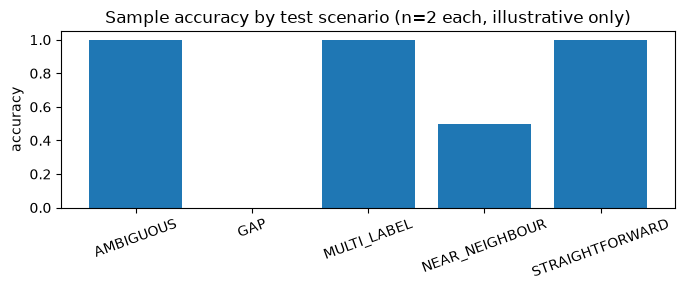

In [13]:
scored = q(f"""
    WITH gold AS (
        SELECT encounter_id,
               MAX(IFF(label_rank = 1, subtheme, NULL)) AS gold_primary,
               MAX(IFF(label_rank = 2, subtheme, NULL)) AS gold_secondary
        FROM GOLD_LABEL WHERE taxonomy_version_id = '{TAX_VERSION}'
        GROUP BY encounter_id
    )
    SELECT d.test_scenario, r.encounter_id,
           r.result:primary_subtheme::VARCHAR AS predicted,
           g.gold_primary                     AS gold,
           EQUAL_NULL(r.result:primary_subtheme::VARCHAR, g.gold_primary) AS correct,
           NULLIF(r.result:secondary_subtheme::VARCHAR, 'NONE') AS predicted_secondary,
           g.gold_secondary,
           r.result:confidence::VARCHAR       AS confidence
    FROM DEMO_SAMPLE d
    JOIN DEMO_RESULT r ON r.encounter_id = d.encounter_id
    LEFT JOIN gold   g ON g.encounter_id = d.encounter_id
    ORDER BY d.test_scenario, r.encounter_id
""")
display(scored)

by_scenario = scored.groupby("test_scenario").agg(n=("correct", "size"), correct=("correct", "sum")).reset_index()
by_scenario["accuracy"] = by_scenario["correct"] / by_scenario["n"]
print(f"overall primary-subtheme accuracy on the sample: "
      f"{scored['correct'].mean():.2f}  ({int(scored['correct'].sum())}/{len(scored)})")

fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(by_scenario["test_scenario"], by_scenario["accuracy"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("accuracy")
ax.set_title(f"Sample accuracy by test scenario (n={SAMPLE_PER_SCENARIO} each, illustrative only)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 9. The gap signal

The GAP test-scenario notes describe a transportation barrier, and v001 has no subtheme for it (section 4).
A small model under a strict enum rarely picks "nothing fits" on its own, so these usually get placed in
the nearest label at reduced confidence.

That is why the production loop (`TAXONOMY_GAP_REVIEW` in `05`) flags `NO_GOOD_MATCH` **or** LOW
confidence across the **whole backlog**. Measured on this build: 100% precision (every flag was a
genuine transportation note) at low recall (5 of 81). You do not need every instance of a missing
concept, you need enough clean examples to name it, and a 10-row sample usually does not have them.
Read the notes below and the missing concept is obvious to a human.

In [14]:
gap = q("""
    SELECT d.test_scenario, r.encounter_id,
           r.result:primary_subtheme::VARCHAR AS forced_label,
           r.result:confidence::VARCHAR       AS confidence,
           (r.result:primary_subtheme::VARCHAR = 'NO_GOOD_MATCH'
             OR r.result:confidence::VARCHAR = 'LOW') AS flagged_by_pipeline_rule,
           r.result:evidence::VARCHAR         AS evidence,
           p.full_text                        AS note_text
    FROM DEMO_RESULT r
    JOIN DEMO_SAMPLE    d ON d.encounter_id = r.encounter_id
    JOIN ENCOUNTER_PREP p ON p.encounter_id = r.encounter_id
    WHERE d.test_scenario = 'GAP'
       OR r.result:primary_subtheme::VARCHAR = 'NO_GOOD_MATCH'
       OR r.result:confidence::VARCHAR IN ('LOW', 'MEDIUM')
    ORDER BY (d.test_scenario = 'GAP') DESC, r.encounter_id
""")
for _, row in gap.iterrows():
    print(f"--- {row.encounter_id}  [{row.test_scenario}]  -> {row.forced_label} ({row.confidence})"
          f"   flagged: {row.flagged_by_pipeline_rule}")
    print(f"NOTE:     {row.note_text}")
    print(f"EVIDENCE: {row.evidence}\n")

--- ENC-00171  [GAP]  -> Unable To Reach Provider Office (MEDIUM)   flagged: False
NOTE:     Caregiver called on behalf of pt, 6 wks s/p cholecystectomy, denies wound issues or pain. States pt needs to get infusions 3x/wk but can't figure out ride situation - can't depend on same person each time, insurance covers it all just can't make the logistics work to get there that many times a week. Advised caregiver to contact pt's oncology office re: transportation resources.
EVIDENCE: Patient "can't figure out ride situation" and "can't make the logistics work to get there that many times a week" for required 3x/wk infusions. Advised to contact oncology office for transportation resources. The core issue is inability to access scheduled treatment due to transportation barriers, which is a care coordination/access problem. While not a direct provider office contact failure, the routing to oncology office for resources suggests this is fundamentally a care coordination gap requiring provider 

## 10. Cost, measured rather than estimated

Joined on the classification statement's `query_id`, the same way `RUN_COST` works for real runs.
`ACCOUNT_USAGE` is asynchronous, so expect nothing for the first few minutes; re-run this cell later
and the numbers backfill. Input tokens dominate because the rubric and enum ride along on every call,
which is why taxonomy size is the real cost lever.

In [15]:
query_ids = [CLASSIFY_QUERY_ID]
cost = q(f"""
    SELECT query_id, tokens, tokens_granular:input::INT AS tokens_input,
           tokens_granular:output::INT AS tokens_output, token_credits
    FROM SNOWFLAKE.ACCOUNT_USAGE.CORTEX_AISQL_USAGE_HISTORY
    WHERE query_id IN ({", ".join("'" + qid + "'" for qid in query_ids)})
""")
if cost.empty:
    print("Not in ACCOUNT_USAGE yet. Re-run this cell in a few minutes.")
else:
    n = len(results)
    row = cost.iloc[0]
    print(f"{int(row.tokens):,} tokens for {n} encounters "
          f"(~{row.tokens / n:,.0f}/encounter, input:output ~{row.tokens_input / max(row.tokens_output, 1):.0f}:1)")
    print(f"{row.token_credits:.5f} credits  ->  ~{row.token_credits * 1000 / n:.2f} credits per 1,000 encounters")
    display(cost)

Not in ACCOUNT_USAGE yet. Re-run this cell in a few minutes.


## 11. Optional: the same thing, governed

Everything above, sections 3 through 8, is what one call does in the real pipeline:

- `EVALUATE_CONFIG` classifies the full gold set with exactly one config (here the champion) as
  an EVALUATION run, so none of it reaches the production output in `ENCOUNTER_THEME`. It writes
  `CLASSIFICATION_RAW` (exact model output for audit), `CLASSIFICATION` (one row per label,
  config and version stamped) and `PIPELINE_RUN` (run log with `query_id`), then scores it with
  `RUN_EVAL` overall and per segment (category of the gold label, gold label count, note length).
- `EVAL_GATE` judges it against the champion's previous eval: an accuracy floor, plus no segment
  with at least 20 encounters dropping more than 0.10. Those segments exist on real data; the test
  scenarios above do not.
- A candidate goes through the same call. `REGISTER_CONFIG` forks a new prompt and/or taxonomy,
  `EVALUATE_CONFIG` scores it against the champion, and `PROMOTE_CONFIG` ships it only if the gate
  passes (or with an override reason that lands in `PROMOTION_LOG`).

**This writes to the pipeline tables.** To get back to the webapp warm-start afterwards, run
`demo/reset_webapp.sql` (free, seconds). It is about 200 model calls. The full 200 matters here:
`RUN_EVAL` counts a missing prediction as wrong, so it refuses a run that didn't attempt every
gold encounter rather than report a misleading accuracy.

In [25]:
if RUN_GOVERNED_PATH:
    # The labeler is only used if the champion's taxonomy has no gold labels yet.
    msg = session.sql("CALL EVALUATE_CONFIG(?, 'openai-gpt-5.2', FALSE)",
                      params=[CONFIG_NAME]).collect()[0][0]
    print(msg)
    eval_id = msg.split(":")[0]
    if not eval_id.startswith("eval_"):
        raise RuntimeError(msg)

    display(q("""
        SELECT g.eval_id, g.config_name, g.taxonomy_version_id, g.subtheme_accuracy,
               g.baseline_config_name, g.baseline_subtheme_accuracy, g.segments_regressed,
               g.gate_note, g.gate_result, s.run_scope, s.run_purpose,
               s.theme_accuracy, s.label_set_f1, s.out_of_taxonomy_labels
        FROM EVAL_GATE g JOIN EVAL_SCORECARD s ON s.eval_id = g.eval_id
        WHERE g.eval_id = ?
    """, [eval_id]))
    display(q("""
        SELECT segment_name, segment_value, n, gated,
               ROUND(subtheme_accuracy, 3) AS subtheme_accuracy,
               ROUND(label_set_f1, 3) AS label_set_f1, ROUND(low_conf_rate, 3) AS low_or_med_conf_rate
        FROM EVAL_SEGMENT_DETAIL
        WHERE eval_id = ?
        ORDER BY segment_name, subtheme_accuracy
    """, [eval_id]))
else:
    print("Skipped (RUN_GOVERNED_PATH = False). Set it True in the setup cell to run the real thing.")

Skipped (RUN_GOVERNED_PATH = False). Set it True in the setup cell to run the real thing.


## 12. What runs unattended in production

In production, new notes land in `NOTE_RAW`, the dynamic table picks them
up, a stream on it records the new encounters, and a scheduled task with a
`WHEN SYSTEM$STREAM_HAS_DATA` guard calls `CLASSIFY_BATCH('STREAM')`, which runs the champion
config, only when there is something to do. A refresh that changes nothing costs nothing. The task
is created suspended so setup doesn't start billing; resume it with
`ALTER TASK CLASSIFY_ENCOUNTERS RESUME` when you're ready.

The LLM step is deliberately a task and not a dynamic table: every row is stamped with the config
and taxonomy version that produced it, and promoting a new champion should be an explicit, costed
re-classification (`CLASSIFY_BATCH('BACKLOG')`) rather than an automatic one.

In [27]:
display(show("SHOW TASKS LIKE 'CLASSIFY_ENCOUNTERS'", ["name", "state", "schedule", "condition", "definition"]))
display(show("SHOW STREAMS LIKE 'ENCOUNTER_PREP_STREAM'", ["name", "source_type", "mode", "stale"]))
q("""
    SELECT 'pipeline runs' AS what, COUNT(*) AS n FROM PIPELINE_RUN
    UNION ALL SELECT 'classification labels', COUNT(*) FROM CLASSIFICATION
    UNION ALL SELECT 'eval runs', COUNT(*) FROM EVAL_RUN
""")

,name,state,schedule,condition,definition
0,CLASSIFY_ENCOUNTERS,suspended,1 MINUTE,SYSTEM$STREAM_HAS_DATA('ENCOUNTER_PREP_STREAM'),CALL CLASSIFY_BATCH('STREAM')


,name,source_type,mode,stale
0,ENCOUNTER_PREP_STREAM,Dynamic Table,DEFAULT,false


,what,n
0,pipeline runs,0
1,classification labels,0
2,eval runs,0


---
The temp tables (`DEMO_SAMPLE`, `DEMO_RESULT`, `DEMO_FREE`) disappear when the session ends. Change
`SAMPLE_SEED` or `SAMPLE_PER_SCENARIO` in the setup cell and re-run all for a different sample.